# Notebook 01 — Dataset Audit and Setup

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Objective:** Inspect the raw dataset, verify file shards and sizes, decode representative TFRecord examples, identify feature dimensions and datatypes, and document the target label and class imbalance.

---
## 1. Project Setup and Environment Verification
We verify Python dependencies and project directory structure before loading the dataset.


In [ ]:
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.append(repo_root)
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import glob
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

import src.data_loader as dl

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

## 2. Raw Dataset Path and File Shards Audit
We inspect the raw TFRecord shards downloaded from Huot et al. (2022) in `data/raw/archive`.


In [ ]:
raw_dir = "data/raw/archive" if os.path.exists("data/raw/archive") else "../data/raw/archive"
splits = ["train", "eval", "test"]
shard_summary = []

for s in splits:
    paths = dl.get_tfrecord_paths(s, raw_dir=raw_dir)
    total_size_mb = sum(os.path.getsize(p) for p in paths) / (1024 * 1024)
    shard_summary.append({
        "Split": s,
        "Shard Count": len(paths),
        "Total Size (MB)": round(total_size_mb, 2),
        "Example Shard": os.path.basename(paths[0]) if paths else "None"
    })

shard_df = pd.DataFrame(shard_summary)
display(shard_df)


,Split,Shard Count,Total Size (MB),Example Shard
0,train,15,3047.19,next_day_wildfire_spread_train_00.tfrecord
1,eval,2,381.84,next_day_wildfire_spread_eval_00.tfrecord
2,test,2,343.60,next_day_wildfire_spread_test_00.tfrecord


## 3. TFRecord Decoding and Feature Schema Inspection
Each sample in the TFRecord file represents a $64 \times 64$ kilometer spatial grid.
We decode the binary `tf.train.Example` protos into 2D numpy arrays and identify all 13 channels.


In [ ]:
train_paths = dl.get_tfrecord_paths("train")
record_gen = dl.iter_records(train_paths, max_records=1)
first_patch = next(record_gen)

schema_info = []
for k in dl.ALL_CHANNELS:
    arr = first_patch[k]
    schema_info.append({
        "Channel": k,
        "Role": "Target" if k == dl.TARGET_NAME else ("Lagged Fire" if k == "PrevFireMask" else "Input Feature"),
        "2D Shape": arr.shape,
        "Total Pixels": arr.size,
        "Data Type": str(arr.dtype),
        "Min Value": round(float(arr.min()), 3),
        "Max Value": round(float(arr.max()), 3),
        "Mean Value": round(float(arr.mean()), 3)
    })

schema_df = pd.DataFrame(schema_info)
display(schema_df)


I0000 00:00:1792988634.687856 2270093 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


,Channel,Role,2D Shape,Total Pixels,Data Type,Min Value,Max Value,Mean Value
0,elevation,Input Feature,"(64, 64)",4096,float32,36.000,141.000,85.028
1,th,Input Feature,"(64, 64)",4096,float32,160.490,190.258,174.234
2,vs,Input Feature,"(64, 64)",4096,float32,2.837,3.327,3.029
3,tmmn,Input Feature,"(64, 64)",4096,float32,275.186,276.462,275.738
4,tmmx,Input Feature,"(64, 64)",4096,float32,292.345,293.491,292.976
5,sph,Input Feature,"(64, 64)",4096,float32,0.004,0.005,0.005
6,pr,Input Feature,"(64, 64)",4096,float32,0.000,0.000,0.000
7,pdsi,Input Feature,"(64, 64)",4096,float32,2.461,4.989,3.718
8,NDVI,Input Feature,"(64, 64)",4096,float32,-2604.000,8548.000,7520.236
9,population,Input Feature,"(64, 64)",4096,float32,0.000,741.326,8.426


## 4. Target Label Verification and Class Imbalance Audit
We examine the distribution of values in `FireMask` (target day $t+1$) and `PrevFireMask` (observation day $t$).
In the Huot et al. (2022) schema:
- `1.0`: Active wildfire burn detection
- `0.0`: Unburned terrain
- `-1.0`: Masked / uncertain / missing satellite observation


In [ ]:
target_arr = first_patch["FireMask"]
prev_arr = first_patch["PrevFireMask"]

vals_target, counts_target = np.unique(target_arr, return_counts=True)
vals_prev, counts_prev = np.unique(prev_arr, return_counts=True)

label_audit = pd.DataFrame({
    "Pixel Value": vals_target,
    "Target (FireMask t+1) Pixels": counts_target,
    "Target Prevalence (%)": np.round((counts_target / len(target_arr.flatten())) * 100, 3),
})
display(label_audit)

print(f"Burn Positives (Day t+1): {np.sum(target_arr == 1.0)}")
print(f"Burn Positives (Day t):   {np.sum(prev_arr == 1.0)}")


,Pixel Value,Target (FireMask t+1) Pixels,Target Prevalence (%)
0,0.0,4089,99.829
1,1.0,7,0.171


Burn Positives (Day t+1): 7
Burn Positives (Day t):   11


## 5. Multi-Sample Label Distribution Across Patches
We inspect 20 consecutive patches to evaluate class imbalance and verify how burn pixels vary across events.


,Patch ID,Day t Fire Pixels,Day t+1 Fire Pixels,Uncertain (-1) Pixels,Burn Prevalence (%)
0,0,11,7,0,0.171
1,1,5,0,0,0.000
2,2,17,7,0,0.171
3,3,3,0,0,0.000
4,4,7,5,0,0.122
5,5,21,5,0,0.122
6,6,2,0,12,0.000
7,7,4,13,0,0.317
8,8,2,0,0,0.000
9,9,10,0,0,0.000


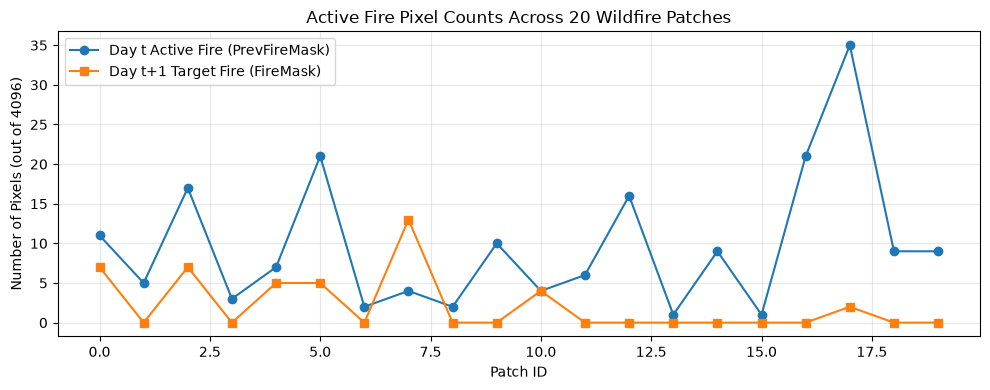

In [ ]:
patch_stats = []
for idx, p in enumerate(dl.iter_records(train_paths, max_records=20)):
    t = p["FireMask"]
    prev = p["PrevFireMask"]
    patch_stats.append({
        "Patch ID": idx,
        "Day t Fire Pixels": int(np.sum(prev == 1.0)),
        "Day t+1 Fire Pixels": int(np.sum(t == 1.0)),
        "Uncertain (-1) Pixels": int(np.sum(t < 0.0)),
        "Burn Prevalence (%)": round(float(np.mean(t == 1.0)) * 100, 3)
    })

patch_df = pd.DataFrame(patch_stats)
display(patch_df.head(10))

plt.figure(figsize=(10, 4))
plt.plot(patch_df["Patch ID"], patch_df["Day t Fire Pixels"], marker="o", label="Day t Active Fire (PrevFireMask)")
plt.plot(patch_df["Patch ID"], patch_df["Day t+1 Fire Pixels"], marker="s", label="Day t+1 Target Fire (FireMask)")
plt.title("Active Fire Pixel Counts Across 20 Wildfire Patches")
plt.xlabel("Patch ID")
plt.ylabel("Number of Pixels (out of 4096)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
fig_dir = "results/figures" if os.path.exists("results/figures") else "../results/figures"
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(os.path.join(fig_dir, "patch_fire_counts_audit.png"), dpi=200)
plt.show()


## 6. Audit Conclusions and Data Contract Conformance
- **Confirmed Inputs**: 11 environmental and weather variables (`elevation`, `th`, `vs`, `tmmn`, `tmmx`, `sph`, `pr`, `pdsi`, `NDVI`, `population`, `erc`) + 1 lagged observation (`PrevFireMask`).
- **Target Label**: `FireMask` binary label for next-day spread.
- **Class Imbalance**: Severe positive sparsity (< 0.5% positive burn pixels per typical patch).
- **Leakage Prevention**: All input features strictly represent conditions up to observation day $t$; target day $t+1$ is isolated.
